In [2]:
# Install the kaggle package so we can download the Titanic data from Python.
# (Only needed once. Make sure it goes into the same Python the notebook uses.)
!pip install kaggle

Defaulting to user installation because normal site-packages is not writeable

   --- ------------------------------------  2/22 [tqdm]
   --- ------------------------------------  2/22 [tqdm]
   --- ------------------------------------  2/22 [tqdm]
   --- ------------------------------------  2/22 [tqdm]
   --- ------------------------------------  2/22 [tqdm]
   --- ------------------------------------  2/22 [tqdm]
   --- ------------------------------------  2/22 [tqdm]
   --- ------------------------------------  2/22 [tqdm]
   ------- --------------------------------  4/22 [pyyaml]
   ------- --------------------------------  4/22 [pyyaml]
   ------- --------------------------------  4/22 [pyyaml]
   ------- --------------------------------  4/22 [pyyaml]
   --------- ------------------------------  5/22 [python-slugify]
   --------- ------------------------------  5/22 [python-slugify]
   ---------- -----------------------------  6/22 [python-dotenv]
   ---------- ---------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] T

In [9]:
# Decide where the data lives. On Kaggle's servers it is already in ../input/titanic.
# On your own computer we download titanic.zip from Kaggle (needs your API token) and unzip it
# into a local 'titanic' folder - but only if that folder doesn't exist yet.
import os
from pathlib import Path

iskaggle = os.environ.get('KAGGLE_KERNEL_RUN_TYPE', '')
if iskaggle: path = Path('../input/titanic')
else:
    path = Path('titanic')
    if not path.exists():
        import zipfile,kaggle
        kaggle.api.competition_download_cli(str(path))
        zipfile.ZipFile(f'{path}.zip').extractall(path)

100%|██████████| 34.1k/34.1k [00:00<00:00, 16.8MB/s]

In [10]:
# Import the tools we need: torch (tensors + gradients), numpy (arrays), pandas (tables).
# The set_printoptions lines just make printed output wider and neater - they don't change any maths.
import torch, numpy as np, pandas as pd
np.set_printoptions(linewidth=140)
torch.set_printoptions(linewidth=140, sci_mode=False, edgeitems=7)
pd.set_option('display.width', 140)

In [11]:
# Load the training data: one row per passenger, with a 'Survived' column (1 = lived, 0 = died).
df = pd.read_csv(path/'train.csv')
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [12]:
# Count missing values in each column. Age, Cabin and Embarked have gaps we must fill,
# because a model can't do maths on blanks.
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [13]:
# For every column, find the most common value (the 'mode').
# We will use these as the default to fill in blanks.
modes = df.mode().iloc[0]
modes

PassengerId                      1
Survived                       0.0
Pclass                         3.0
Name           Abbing, Mr. Anthony
Sex                           male
Age                           24.0
SibSp                          0.0
Parch                          0.0
Ticket                        1601
Fare                          8.05
Cabin                      B96 B98
Embarked                         S
Name: 0, dtype: object

In [14]:
# Fill every blank with that column's most common value.
# Simple and crude, but good enough for this from-scratch exercise.
df.fillna(modes, inplace=True)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,B96 B98,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,B96 B98,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,B96 B98,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,B96 B98,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,24.0,1,2,W./C. 6607,23.4500,B96 B98,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [15]:
# Check again: every column should now show 0 missing values.
df.isna().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

In [16]:
# Summary stats (mean, min, max...) of the numeric columns, to get a feel for the data.
import numpy as np

df.describe(include=(np.number))

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,28.566970,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.199572,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,24.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


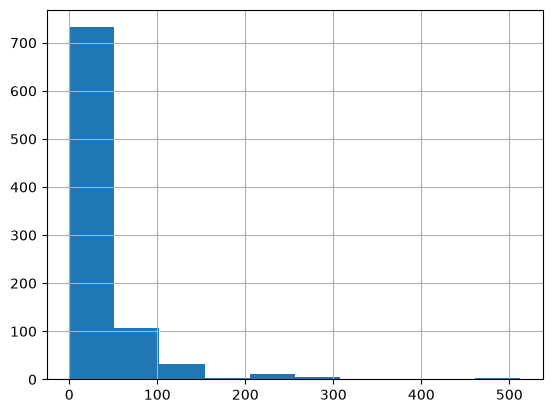

In [17]:
# Histogram of ticket prices. Most fares are small and a few are huge,
# so the picture is very lopsided.
df['Fare'].hist();

In [18]:
# Take the log of the fare (+1 so a fare of 0 doesn't break log).
# This squashes the huge values together so a few rich passengers don't dominate.
df['LogFare'] = np.log(df['Fare']+1)

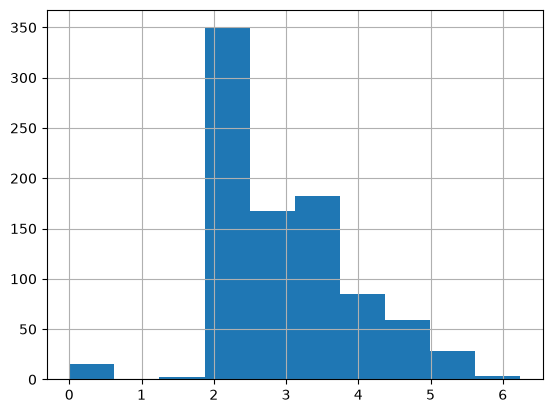

In [19]:
# Histogram of the log fare - it is much more evenly spread than the raw fare.
df['LogFare'].hist();

In [20]:
# List the passenger classes that exist (1st, 2nd, 3rd).
pclasses = sorted(df.Pclass.unique())
pclasses

[np.int64(1), np.int64(2), np.int64(3)]

In [21]:
# Summary of the text columns (Name, Sex, Ticket, Cabin, Embarked): how many unique values, most common one.
df.describe(include=[object])

C:\Users\Pranav\AppData\Local\Temp\ipykernel_3216\419507111.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=[object])


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,891,891
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,B96 B98,S
freq,1,577,7,691,646


In [ ]:
# Models need numbers, not words. 'Sex', 'Pclass' and 'Embarked' are categories, so we turn each
# into separate 0/1 columns (e.g. Sex_male, Sex_female). This is called 'one-hot' encoding.
# dtype=float makes them 0.0/1.0 instead of True/False, which PyTorch needs.
df = pd.get_dummies(df, columns=["Sex","Pclass","Embarked"], dtype=float)
df.columns

In [23]:
# Keep a list of the new 0/1 columns, and peek at the first rows to check them.
added_cols = ['Sex_male', 'Sex_female', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Embarked_C', 'Embarked_Q', 'Embarked_S']
df[added_cols].head()

,Sex_male,Sex_female,Pclass_1,Pclass_2,Pclass_3,Embarked_C,Embarked_Q,Embarked_S
0,True,False,False,False,True,False,False,True
1,False,True,True,False,False,True,False,False
2,False,True,False,False,True,False,False,True
3,False,True,True,False,False,False,False,True
4,True,False,False,False,True,False,False,True


In [24]:
# The thing we want to predict (Survived) as a PyTorch tensor. 'dep' = dependent variable.
from torch import tensor

t_dep = tensor(df.Survived)

In [31]:
# The inputs we will feed the model: age, siblings/spouses, parents/children, log fare, plus the 0/1 columns.
# 'indep' = independent variables. We print their types to check they are numeric.
indep_cols = ['Age', 'SibSp', 'Parch', 'LogFare'] + added_cols
df[indep_cols].dtypes


Age           float64
SibSp           int64
Parch           int64
LogFare       float64
Sex_male         bool
Sex_female       bool
Pclass_1         bool
Pclass_2         bool
Pclass_3         bool
Embarked_C       bool
Embarked_Q       bool
Embarked_S       bool
dtype: object

In [33]:
# Turn the input table into one big float tensor (rows = passengers, columns = inputs).
# astype(float) is the fix for the 'object' error: it converts any True/False columns to numbers.
indep_cols = ['Age', 'SibSp', 'Parch', 'LogFare'] + added_cols

t_indep = tensor(df[indep_cols].astype(float).values, dtype=torch.float)
t_indep

tensor([[22.0000,  1.0000,  0.0000,  2.1102,  1.0000,  0.0000,  0.0000,  0.0000,  1.0000,  0.0000,  0.0000,  1.0000],
        [38.0000,  1.0000,  0.0000,  4.2806,  0.0000,  1.0000,  1.0000,  0.0000,  0.0000,  1.0000,  0.0000,  0.0000],
        [26.0000,  0.0000,  0.0000,  2.1889,  0.0000,  1.0000,  0.0000,  0.0000,  1.0000,  0.0000,  0.0000,  1.0000],
        [35.0000,  1.0000,  0.0000,  3.9908,  0.0000,  1.0000,  1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  1.0000],
        [35.0000,  0.0000,  0.0000,  2.2028,  1.0000,  0.0000,  0.0000,  0.0000,  1.0000,  0.0000,  0.0000,  1.0000],
        [24.0000,  0.0000,  0.0000,  2.2469,  1.0000,  0.0000,  0.0000,  0.0000,  1.0000,  0.0000,  1.0000,  0.0000],
        [54.0000,  0.0000,  0.0000,  3.9677,  1.0000,  0.0000,  1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  1.0000],
        ...,
        [25.0000,  0.0000,  0.0000,  2.0857,  1.0000,  0.0000,  0.0000,  0.0000,  1.0000,  0.0000,  0.0000,  1.0000],
        [39.0000,  0.0000,  5.0000,  3.4054

In [34]:
# Shape check: 891 passengers x 12 input columns.
t_indep.shape

torch.Size([891, 12])

In [35]:
# Start the model with random numbers: one 'coefficient' (weight) per input column.
# Each is random between -0.5 and 0.5. Training will adjust them. The seed makes it repeatable.
torch.manual_seed(442)

n_coeff = t_indep.shape[1]
coeffs = torch.rand(n_coeff)-0.5
coeffs

tensor([-0.4629,  0.1386,  0.2409, -0.2262, -0.2632, -0.3147,  0.4876,  0.3136,  0.2799, -0.4392,  0.2103,  0.3625])

In [36]:
# Multiply each input by its coefficient. Notice Age is huge (e.g. -10) next to the 0/1 columns,
# so Age would swamp everything. That is a scale problem, fixed in the next cell.
t_indep*coeffs

tensor([[-10.1838,   0.1386,   0.0000,  -0.4772,  -0.2632,  -0.0000,   0.0000,   0.0000,   0.2799,  -0.0000,   0.0000,   0.3625],
        [-17.5902,   0.1386,   0.0000,  -0.9681,  -0.0000,  -0.3147,   0.4876,   0.0000,   0.0000,  -0.4392,   0.0000,   0.0000],
        [-12.0354,   0.0000,   0.0000,  -0.4950,  -0.0000,  -0.3147,   0.0000,   0.0000,   0.2799,  -0.0000,   0.0000,   0.3625],
        [-16.2015,   0.1386,   0.0000,  -0.9025,  -0.0000,  -0.3147,   0.4876,   0.0000,   0.0000,  -0.0000,   0.0000,   0.3625],
        [-16.2015,   0.0000,   0.0000,  -0.4982,  -0.2632,  -0.0000,   0.0000,   0.0000,   0.2799,  -0.0000,   0.0000,   0.3625],
        [-11.1096,   0.0000,   0.0000,  -0.5081,  -0.2632,  -0.0000,   0.0000,   0.0000,   0.2799,  -0.0000,   0.2103,   0.0000],
        [-24.9966,   0.0000,   0.0000,  -0.8973,  -0.2632,  -0.0000,   0.4876,   0.0000,   0.0000,  -0.0000,   0.0000,   0.3625],
        ...,
        [-11.5725,   0.0000,   0.0000,  -0.4717,  -0.2632,  -0.0000,   0.0000

In [37]:
# Divide each column by its own maximum, so every column ends up between 0 and 1.
# 'vals' stores those maximums - we must reuse the SAME vals for the test data later.
vals,indices = t_indep.max(dim=0)
t_indep = t_indep / vals

In [38]:
# Same multiplication as before: the numbers are now all a similar size.
t_indep*coeffs

tensor([[-0.1273,  0.0173,  0.0000, -0.0765, -0.2632, -0.0000,  0.0000,  0.0000,  0.2799, -0.0000,  0.0000,  0.3625],
        [-0.2199,  0.0173,  0.0000, -0.1551, -0.0000, -0.3147,  0.4876,  0.0000,  0.0000, -0.4392,  0.0000,  0.0000],
        [-0.1504,  0.0000,  0.0000, -0.0793, -0.0000, -0.3147,  0.0000,  0.0000,  0.2799, -0.0000,  0.0000,  0.3625],
        [-0.2025,  0.0173,  0.0000, -0.1446, -0.0000, -0.3147,  0.4876,  0.0000,  0.0000, -0.0000,  0.0000,  0.3625],
        [-0.2025,  0.0000,  0.0000, -0.0798, -0.2632, -0.0000,  0.0000,  0.0000,  0.2799, -0.0000,  0.0000,  0.3625],
        [-0.1389,  0.0000,  0.0000, -0.0814, -0.2632, -0.0000,  0.0000,  0.0000,  0.2799, -0.0000,  0.2103,  0.0000],
        [-0.3125,  0.0000,  0.0000, -0.1438, -0.2632, -0.0000,  0.4876,  0.0000,  0.0000, -0.0000,  0.0000,  0.3625],
        ...,
        [-0.1447,  0.0000,  0.0000, -0.0756, -0.2632, -0.0000,  0.0000,  0.0000,  0.2799, -0.0000,  0.0000,  0.3625],
        [-0.2257,  0.0000,  0.2008, -0.1234

In [39]:
# NOTE: this divides by vals a SECOND time (already done in the cell above).
# It looks like an accidental duplicate and shrinks the training inputs twice as much as the test inputs.
t_indep = t_indep / vals


In [40]:
# The model's prediction for each passenger: multiply inputs by coefficients, then add them up.
preds = (t_indep*coeffs).sum(axis=1)

In [41]:
# Look at the first 10 predictions.
preds[:10]

tensor([ 0.3675, -0.2917,  0.3131,  0.5119,  0.3638,  0.2121,  0.5599,  0.3742,  0.3246, -0.4591])

In [42]:
# The loss: how wrong we are on average (average absolute gap between prediction and truth).
# Lower is better. Training = making this number smaller.
loss = torch.abs(preds-t_dep).mean()
loss

tensor(0.5415)

In [61]:
# Wrap the prediction and loss steps into reusable functions.
def calc_preds(coeffs, indeps): return (indeps*coeffs).sum(axis=1)
def calc_loss(coeffs, indeps, deps): return torch.abs(calc_preds(coeffs, indeps)-deps).mean()

In [62]:
# Tell PyTorch to track how the loss changes when each coefficient changes (gradients).
coeffs.requires_grad_()

tensor([-0.4620,  0.1377,  0.2451, -0.1862, -0.4198,  0.2177,  0.6980,  0.3781,  0.3809,  0.0702,  0.2114,  0.2279], requires_grad=True)

In [45]:
# Calculate the loss again, now with gradient tracking turned on.
loss = calc_loss(coeffs, t_indep, t_dep)
loss

tensor(0.5415, grad_fn=<MeanBackward0>)

In [46]:
# backward() works out, for each coefficient, which direction makes the loss go up or down.
loss.backward()

In [47]:
# Show those gradients (one per coefficient).
coeffs.grad

tensor([ 0.0003,  0.0018, -0.0005, -0.0034,  0.2548, -0.1908, -0.1212, -0.0067,  0.1919, -0.1886,  0.0191,  0.2334])

In [48]:
# Do it again. Notice the gradients are exactly doubled: PyTorch ADDS new gradients to old ones
# unless you reset them. That is why we zero them after every update below.
loss = calc_loss(coeffs, t_indep, t_dep)
loss.backward()
coeffs.grad

tensor([ 0.0007,  0.0036, -0.0010, -0.0069,  0.5095, -0.3816, -0.2424, -0.0135,  0.3838, -0.3771,  0.0382,  0.4669])

In [49]:
# One step of gradient descent: nudge every coefficient a little in the direction that lowers the loss
# (step size 0.1), reset the gradients, and print the new, smaller loss.
loss = calc_loss(coeffs, t_indep, t_dep)
loss.backward()
with torch.no_grad():
    coeffs.sub_(coeffs.grad * 0.1)
    coeffs.grad.zero_()
    print(calc_loss(coeffs, t_indep, t_dep))

tensor(0.4685)


In [51]:
# Randomly split the rows: 80% to train on, 20% held back to check the model on data it hasn't seen.
# (Plain-torch version of fastai's RandomSplitter, same seed so the split is repeatable.)
torch.manual_seed(42)
idxs = torch.randperm(len(df))
cut = int(0.2 * len(df))
trn_split, val_split = idxs[cut:], idxs[:cut]

In [52]:
# Build the training and validation sets from those row numbers: 713 train, 178 validation.
trn_indep,val_indep = t_indep[trn_split],t_indep[val_split]
trn_dep,val_dep = t_dep[trn_split],t_dep[val_split]
len(trn_indep),len(val_indep)

(713, 178)

In [53]:
# The update step as a function: move coefficients against the gradient, then zero the gradient.
def update_coeffs(coeffs, lr):
    coeffs.sub_(coeffs.grad * lr)
    coeffs.grad.zero_()

In [54]:
# One epoch = one full pass over the training data: compute loss, get gradients, update, print the loss.
def one_epoch(coeffs, lr):
    loss = calc_loss(coeffs, trn_indep, trn_dep)
    loss.backward()
    with torch.no_grad(): update_coeffs(coeffs, lr)
    print(f"{loss:.3f}", end="; ")

In [55]:
# Create fresh random starting coefficients that PyTorch will track gradients for.
def init_coeffs(): return (torch.rand(n_coeff)-0.5).requires_grad_()

In [56]:
# Train: start from random coefficients and repeat 'one_epoch' many times.
# lr (learning rate) is how big each step is. Too big overshoots, too small is slow.
def train_model(epochs=30, lr=0.01):
    torch.manual_seed(442)
    coeffs = init_coeffs()
    for i in range(epochs): one_epoch(coeffs, lr=lr)
    return coeffs

In [57]:
# Train for 18 epochs at learning rate 0.2. The printed loss should keep going down.
coeffs = train_model(18, lr=0.2)

0.539; 0.492; 0.444; 0.419; 0.426; 0.379; 0.386; 0.367; 0.340; 0.358; 0.311; 0.354; 0.329; 0.301; 0.323; 0.283; 0.304; 0.285; 

In [58]:
# Show each input column next to the coefficient the model learned for it.
# Big positive = pushes toward survival, big negative = pushes toward death.
def show_coeffs(): return dict(zip(indep_cols, coeffs.requires_grad_(False)))
show_coeffs()

{'Age': tensor(-0.4620),
 'SibSp': tensor(0.1377),
 'Parch': tensor(0.2451),
 'LogFare': tensor(-0.1862),
 'Sex_male': tensor(-0.4198),
 'Sex_female': tensor(0.2177),
 'Pclass_1': tensor(0.6980),
 'Pclass_2': tensor(0.3781),
 'Pclass_3': tensor(0.3809),
 'Embarked_C': tensor(0.0702),
 'Embarked_Q': tensor(0.2114),
 'Embarked_S': tensor(0.2279)}

In [64]:
# Predict on the validation passengers (data the model never trained on).
preds = calc_preds(coeffs, val_indep)
preds

tensor([0.7931, 0.1604, 0.0195, 0.1643, 0.1718, 0.1711, 0.6625, 0.8090, 0.1948, 0.6609, 0.1762, 0.0252, 0.1857, 0.7978, 0.1769, 0.4870,
        0.4855, 0.8129, 0.1676, 0.8133, 0.1768, 0.4862, 0.9695, 0.8159, 0.1776, 0.1575, 0.8234, 0.4858, 0.1769, 0.7979, 0.8233, 0.8311,
        0.1771, 0.1762, 0.7926, 0.8319, 0.4857, 0.9638, 0.1767, 0.8163, 0.1731, 0.1767, 0.1814, 0.9628, 0.1770, 0.8398, 0.1677, 0.1780,
        0.1609, 0.8147, 0.4692, 0.1942, 0.1939, 0.1772, 0.1726, 0.1722, 0.1604, 0.1751, 0.1769, 0.1733, 0.3302, 0.1799, 0.4839, 0.1770,
        0.8069, 0.4905, 0.1718, 0.1707, 0.1652, 0.8076, 0.1766, 0.6673, 0.1723, 0.1760, 0.4886, 0.1774, 0.1767, 0.4839, 0.1722, 0.1695,
        0.1796, 0.9757, 0.1769, 0.1771, 0.8084, 0.0246, 0.3268, 1.1354, 0.6507, 0.1719, 0.1760, 0.1767, 0.9614, 0.0191, 0.6655, 0.0134,
        0.1671, 0.7973, 0.7980, 0.1613, 0.1862, 0.7979, 0.1762, 0.1764, 0.4866, 0.1705, 0.1756, 0.8121, 0.3272, 0.1791, 0.8191, 0.8123,
        0.4879, 1.1053, 0.1767, 0.9630, 0.8285, 

In [65]:
# Turn predictions into yes/no: above 0.5 means 'survived'. Compare to the truth (True = correct guess).
results = val_dep.bool()==(preds>0.5)
results[:16]

tensor([ True,  True,  True,  True,  True,  True,  True,  True,  True,  True, False, False, False,  True,  True, False])

In [66]:
# Accuracy = fraction of correct guesses on the validation set.
results.float().mean()

tensor(0.7865)

In [67]:
# The same accuracy calculation wrapped in a function, so we can reuse it after retraining.
def acc(coeffs): return (val_dep.bool()==(calc_preds(coeffs, val_indep)>0.5)).float().mean()
acc(coeffs)

tensor(0.7865)

In [68]:
# Look at some predictions. Some are below 0 or above 1, which makes no sense for a probability.
# That is the motivation for the sigmoid in the cells below.
preds[:28]

tensor([0.7931, 0.1604, 0.0195, 0.1643, 0.1718, 0.1711, 0.6625, 0.8090, 0.1948, 0.6609, 0.1762, 0.0252, 0.1857, 0.7978, 0.1769, 0.4870,
        0.4855, 0.8129, 0.1676, 0.8133, 0.1768, 0.4862, 0.9695, 0.8159, 0.1776, 0.1575, 0.8234, 0.4858], grad_fn=<SliceBackward0>)

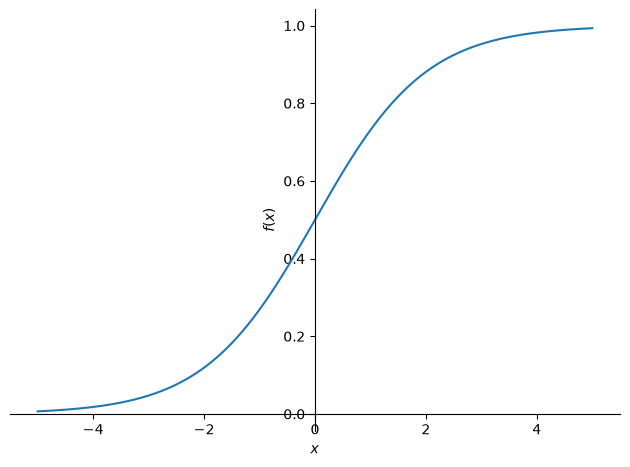

In [73]:
# Plot the sigmoid curve 1/(1+e^-x): it squashes any number into a value between 0 and 1.
import sympy
from sympy.abc import x

sympy.plot(1 / (1 + sympy.exp(-x)), (x, -5, 5))

In [74]:
# Redefine predictions to pass the sum through sigmoid, so every output is between 0 and 1
# (like a probability of survival).
def calc_preds(coeffs, indeps): return torch.sigmoid((indeps*coeffs).sum(axis=1))

In [75]:
# Retrain with the sigmoid. The learning rate is huge (100) because sigmoid outputs change slowly
# and the gradients are tiny. The loss now drops to about 0.19.
coeffs = train_model(lr=100)

0.524; 0.291; 0.211; 0.203; 0.199; 0.198; 0.198; 0.197; 0.197; 0.196; 0.196; 0.196; 0.196; 0.195; 0.195; 0.195; 0.195; 0.195; 0.195; 0.195; 0.195; 0.195; 0.194; 0.194; 0.194; 0.194; 0.194; 0.194; 0.194; 0.194; 

In [76]:
# Validation accuracy after the sigmoid change (about 0.83, better than before).
acc(coeffs)


tensor(0.8258)

In [77]:
# The learned coefficients. Sex_male is strongly negative and Sex_female strongly positive,
# matching the known pattern that women survived far more often.
show_coeffs()

{'Age': tensor(-0.4786),
 'SibSp': tensor(-0.0450),
 'Parch': tensor(0.1119),
 'LogFare': tensor(-0.2008),
 'Sex_male': tensor(-10.1734),
 'Sex_female': tensor(7.9806),
 'Pclass_1': tensor(3.3944),
 'Pclass_2': tensor(2.2695),
 'Pclass_3': tensor(-6.1976),
 'Embarked_C': tensor(1.4253),
 'Embarked_Q': tensor(2.1883),
 'Embarked_S': tensor(-5.0948)}

In [78]:
# Load the test data (passengers whose Survived value we have to guess).
tst_df = pd.read_csv(path/'test.csv')

In [79]:
# The test set has one missing Fare, so set it to 0.
tst_df['Fare'] = tst_df.Fare.fillna(0)

In [85]:
# Apply the SAME preparation to the test data as the training data:
# reload it, fill blanks with the training modes, log the fare, one-hot encode, convert to a tensor,
# and divide by the training 'vals'. Doing it exactly the same way is essential.
# It reloads the file each time so you can safely re-run this cell.
tst_df = pd.read_csv(path/'test.csv')
tst_df['Fare'] = tst_df.Fare.fillna(0)

tst = tst_df.fillna(modes)
tst['LogFare'] = np.log(tst['Fare']+1)
tst = pd.get_dummies(tst, columns=["Sex","Pclass","Embarked"], dtype=float)

tst_indep = tensor(tst[indep_cols].astype(float).values, dtype=torch.float)
tst_indep = tst_indep / vals

In [86]:
# Predict survival for the test passengers: above 0.5 becomes 1, otherwise 0.
# (The arguments are in swapped order versus calc_preds(coeffs, indeps), but the result is
# identical because multiplication doesn't care about order.)
tst_df['Survived'] = (calc_preds(tst_indep, coeffs)>0.5).int()

In [87]:
# Keep only the two columns Kaggle wants (PassengerId, Survived) and save them as sub.csv.
sub_df = tst_df[['PassengerId','Survived']]
sub_df.to_csv('sub.csv', index=False)

In [91]:
# Show the first 5 rows of the file we are about to submit.
pd.read_csv('sub.csv').head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0


In [92]:
# Upload sub.csv to the Titanic competition on Kaggle straight from the notebook.
# The second argument is just a note describing this attempt.
import kaggle
kaggle.api.competition_submit("sub.csv", "pytorch from scratch", "titanic")

100%|██████████| 3.18k/3.18k [00:01<00:00, 3.00kB/s]


{"message": "Successfully submitted to Titanic - Machine Learning from Disaster", "ref": 57663206}

In [93]:
# The 'multiply then add up' prediction, written the long way (this is what a linear model does).
(val_indep*coeffs).sum(axis=1)

tensor([ 12.4232, -14.1957, -14.9584, -13.0223, -13.0142, -13.0179,   3.1973,   5.1396, -21.4831,   3.1926, -21.4795, -14.9595, -21.4766,
          3.9582, -21.4787, -11.8943, -11.8958,   5.1395, -13.0186,  -3.3258, -21.4789, -11.8951,  12.7754,   5.1356, -21.4781, -14.2018,
         -3.3224, -11.8955, -21.4788,   3.9583,   5.1466,  -3.3303, -21.4785, -21.4794,  12.4228,  -3.3265, -11.8957,  12.7765, -21.4790,
         -3.3257, -13.0127, -21.4790, -13.0122,  12.7754, -21.4787,  -3.3184, -21.4886, -21.4836, -14.1952,  -3.3243,  -4.6187, -21.4837,
        -21.4810, -21.4784, -13.0132, -13.0137, -14.1957, -21.4837, -21.4787, -21.4826,  -5.3733, -21.4785, -11.8975, -21.4787,   5.1343,
        -11.8947, -13.0141, -21.4853, -14.1978,   5.1381, -21.4790,   3.1983, -13.0136, -21.4797, -11.8926, -21.4782, -21.4790, -11.9006,
        -13.0137, -13.0165, -13.0161,  12.7747, -21.4788, -21.4785,   5.1390,  -6.4943,  -5.3800,   6.2599,  11.6560, -13.0140, -21.4797,
        -21.4790,  12.7739, -14.95

In [94]:
# The same thing with '@', which is matrix multiplication. One short operator, same numbers,
# and it is much faster - and it is what lets us build bigger models next.
val_indep@coeffs

tensor([ 12.4232, -14.1957, -14.9584, -13.0223, -13.0142, -13.0179,   3.1973,   5.1396, -21.4831,   3.1926, -21.4795, -14.9595, -21.4766,
          3.9582, -21.4787, -11.8943, -11.8958,   5.1395, -13.0186,  -3.3258, -21.4789, -11.8951,  12.7754,   5.1356, -21.4780, -14.2018,
         -3.3224, -11.8955, -21.4788,   3.9583,   5.1466,  -3.3303, -21.4785, -21.4794,  12.4228,  -3.3265, -11.8957,  12.7765, -21.4790,
         -3.3257, -13.0127, -21.4790, -13.0122,  12.7754, -21.4787,  -3.3184, -21.4886, -21.4836, -14.1952,  -3.3243,  -4.6187, -21.4837,
        -21.4810, -21.4784, -13.0132, -13.0137, -14.1957, -21.4837, -21.4787, -21.4826,  -5.3733, -21.4785, -11.8975, -21.4787,   5.1343,
        -11.8947, -13.0141, -21.4853, -14.1978,   5.1381, -21.4790,   3.1983, -13.0136, -21.4797, -11.8926, -21.4782, -21.4790, -11.9006,
        -13.0137, -13.0165, -13.0161,  12.7747, -21.4788, -21.4785,   5.1390,  -6.4943,  -5.3800,   6.2599,  11.6560, -13.0140, -21.4797,
        -21.4790,  12.7739, -14.95

In [95]:
# Redefine predictions using '@' instead of multiply-and-sum, still squashed by sigmoid.
def calc_preds(coeffs, indeps): return torch.sigmoid(indeps@coeffs)

In [96]:
# New starting coefficients, shaped as a column (12 x 1) because '@' needs matching shapes.
# Small random values between 0 and 0.1.
def init_coeffs(): return (torch.rand(n_coeff, 1)*0.1).requires_grad_()

In [97]:
# '[:,None]' turns each answer list into a column (178 x 1) so it lines up with the new predictions.
trn_dep = trn_dep[:,None]
val_dep = val_dep[:,None]

In [98]:
# Retrain the matrix-multiplication version of the plain linear model.
coeffs = train_model(lr=100)

0.512; 0.296; 0.212; 0.202; 0.198; 0.198; 0.197; 0.197; 0.196; 0.196; 0.196; 0.196; 0.195; 0.195; 0.195; 0.195; 0.195; 0.195; 0.195; 0.195; 0.194; 0.194; 0.194; 0.194; 0.194; 0.194; 0.194; 0.194; 0.194; 0.194; 

In [99]:
# Validation accuracy of that model (should be similar to before - it is the same model, just faster).
acc(coeffs)

tensor(0.8258)

In [100]:
# Now a real (small) neural network: instead of one set of coefficients we make TWO layers.
# layer1 turns the 12 inputs into 20 'hidden' numbers (20 little detectors for patterns),
# layer2 combines those 20 numbers into 1 final answer, plus a constant (bias) added at the end.
# The starting values are small and random so training begins gently.
def init_coeffs(n_hidden=20):
    layer1 = (torch.rand(n_coeff, n_hidden)-0.5)/n_hidden
    layer2 = torch.rand(n_hidden, 1)-0.3
    const = torch.rand(1)[0]
    return layer1.requires_grad_(),layer2.requires_grad_(),const.requires_grad_()

In [101]:
# Predictions through the 2-layer network:
# 1) multiply inputs by layer1, 2) relu = replace every negative number with 0 (this is what lets the
# network learn curved, non-linear patterns), 3) multiply by layer2 and add the constant,
# 4) sigmoid squashes the result to between 0 and 1.
import torch.nn.functional as F

def calc_preds(coeffs, indeps):
    l1,l2,const = coeffs
    res = F.relu(indeps@l1)
    res = res@l2 + const
    return torch.sigmoid(res)

In [102]:
# Update step for several layers: nudge each layer's numbers against its gradient, then reset the gradients.
def update_coeffs(coeffs, lr):
    for layer in coeffs:
        layer.sub_(layer.grad * lr)
        layer.grad.zero_()

In [103]:
# Train the 2-layer network with a small learning rate (1.4).
coeffs = train_model(lr=1.4)

0.544; 0.533; 0.521; 0.507; 0.491; 0.470; 0.445; 0.416; 0.384; 0.352; 0.325; 0.304; 0.288; 0.275; 0.265; 0.256; 0.250; 0.245; 0.240; 0.237; 0.234; 0.231; 0.229; 0.227; 0.226; 0.225; 0.223; 0.222; 0.221; 0.220; 

In [104]:
# Train the 2-layer network again with a much larger learning rate (20) to compare how step size changes the result.
coeffs = train_model(lr=20)

0.544; 0.416; 0.256; 0.311; 0.212; 0.200; 0.198; 0.197; 0.196; 0.195; 0.194; 0.194; 0.194; 0.193; 0.193; 0.193; 0.193; 0.193; 0.193; 0.193; 0.193; 0.193; 0.193; 0.193; 0.193; 0.193; 0.193; 0.193; 0.193; 0.193; 

In [105]:
# Validation accuracy of the 2-layer network.
acc(coeffs)

tensor(0.8258)

In [106]:
# Build a deeper network of any shape. 'hiddens' lists the size of each hidden layer, e.g. [10, 10]
# is two hidden layers of 10 detectors each. It creates one weight matrix per layer plus one constant
# per layer, with random starting values scaled so training stays stable.
def init_coeffs():
    hiddens = [10, 10]  # <-- set this to the size of each hidden layer you want
    sizes = [n_coeff] + hiddens + [1]
    n = len(sizes)
    layers = [(torch.rand(sizes[i], sizes[i+1])-0.3)/sizes[i+1]*4 for i in range(n-1)]
    consts = [(torch.rand(1)[0]-0.5)*0.1 for i in range(n-1)]
    for l in layers+consts: l.requires_grad_()
    return layers,consts

In [107]:
# Predictions through any number of layers: multiply by each layer and add its constant,
# apply relu after every layer except the last, then sigmoid at the very end.
import torch.nn.functional as F

def calc_preds(coeffs, indeps):
    layers,consts = coeffs
    n = len(layers)
    res = indeps
    for i,l in enumerate(layers):
        res = res@l + consts[i]
        if i!=n-1: res = F.relu(res)
    return torch.sigmoid(res)

In [108]:
# Update step for the deep network: loop over every layer and constant, nudge, reset gradients.
def update_coeffs(coeffs, lr):
    layers,consts = coeffs
    for layer in layers+consts:
        layer.sub_(layer.grad * lr)
        layer.grad.zero_()

In [109]:
# Train the deeper network (learning rate 4).
coeffs = train_model(lr=4)

0.526; 0.483; 0.464; 0.378; 0.373; 0.361; 0.346; 0.356; 0.304; 0.214; 0.209; 0.207; 0.210; 0.202; 0.203; 0.202; 0.204; 0.198; 0.196; 0.195; 0.195; 0.194; 0.194; 0.194; 0.194; 0.194; 0.194; 0.194; 0.193; 0.193; 

In [110]:
# Validation accuracy of the deeper network.
acc(coeffs)

tensor(0.8258)